<a href="https://colab.research.google.com/github/Kokilakoki8398/Kokila/blob/main/Cryptocurrency_Prediction_with_Artificial_Intelligence.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Create a synthetic dataset replicating the structure of your original XRP data
np.random.seed(42)
n_days = 1334
start_date = datetime(2018, 5, 4)
date_list = [start_date + timedelta(days=x) for x in range(n_days)]

# Simulating price movement
close_prices = [0.8]  # Starting price
for _ in range(1, n_days):
    change = np.random.normal(0, 0.03)  # Daily volatility
    close_prices.append(max(0.1, close_prices[-1] * (1 + change)))

open_prices = [p * np.random.uniform(0.98, 1.02) for p in close_prices]
high_prices = [max(o, c) * np.random.uniform(1.0, 1.05) for o, c in zip(open_prices, close_prices)]
low_prices = [min(o, c) * np.random.uniform(0.95, 1.0) for o, c in zip(open_prices, close_prices)]
vol_xrp = np.random.exponential(1e6, n_days)
vol_usdt = vol_xrp * np.array(close_prices) * np.random.uniform(0.9, 1.1)

df_synthetic = pd.DataFrame({
    'date': [d.strftime('%Y-%m-%d') for d in reversed(date_list)],
    'high': high_prices[::-1],
    'low': low_prices[::-1],
    'open': open_prices[::-1],
    'Volume XRP': vol_xrp[::-1],
    'Volume USDT': vol_usdt[::-1],
    'close': close_prices[::-1]
})

# Save the file to the path expected by the pipeline
df_synthetic.to_csv('/content/12 (2).csv', index=False)
print('Synthetic dataset successfully created at /content/12 (2).csv')

Synthetic dataset successfully created at /content/12 (2).csv


In [1]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dense, Dropout, LSTM
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

In [19]:
data = pd.read_csv("/content/12 (2).csv")
print(data.head(0))
data = data.loc[:,['date','high','low','open','Volume XRP','Volume USDT','close']]
print(data.head(5))
print(data.date)

Empty DataFrame
Columns: [date, high, low, open, Volume XRP, Volume USDT, close]
Index: []
         date      high       low      open    Volume XRP   Volume USDT  \
0  2021-12-27  2.039403  1.949169  2.019698  6.676404e+05  1.459401e+06   
1  2021-12-26  2.051614  2.006001  2.038948  2.296486e+05  5.052259e+05   
2  2021-12-25  2.039570  1.967771  1.989271  2.055081e+04  4.361693e+04   
3  2021-12-24  1.918283  1.834888  1.904445  1.307562e+06  2.653317e+06   
4  2021-12-23  1.930894  1.843073  1.845996  4.829816e+05  9.627429e+05   

      close  
0  2.032173  
1  2.045270  
2  1.973127  
3  1.886494  
4  1.853142  
0       2021-12-27
1       2021-12-26
2       2021-12-25
3       2021-12-24
4       2021-12-23
           ...    
1329    2018-05-08
1330    2018-05-07
1331    2018-05-06
1332    2018-05-05
1333    2018-05-04
Name: date, Length: 1334, dtype: object


In [6]:
data = data.set_index('date')
data.index = pd.to_datetime(data.index,unit='ns')
print(data.index)

DatetimeIndex(['2021-12-27', '2021-12-26', '2021-12-25', '2021-12-24',
               '2021-12-23', '2021-12-22', '2021-12-21', '2021-12-20',
               '2021-12-19', '2021-12-18',
               ...
               '2018-05-13', '2018-05-12', '2018-05-11', '2018-05-10',
               '2018-05-09', '2018-05-08', '2018-05-07', '2018-05-06',
               '2018-05-05', '2018-05-04'],
              dtype='datetime64[ns]', name='date', length=1334, freq=None)


In [7]:
aim = 'close'

In [8]:


train_data = data.iloc[200:]
test_data = data.iloc[:200]

def line_plot(line1, line2, label1=None, label2=None, title='', lw=2):
    fig, ax = plt.subplots(1, figsize=(13, 7))
    ax.plot(line1, label=label1, linewidth=lw)
    ax.plot(line2, label=label2, linewidth=lw)
    ax.set_ylabel('XRP/USDT', fontsize=14)
    ax.set_title(title, fontsize=16)
    ax.legend(loc='best', fontsize=16);

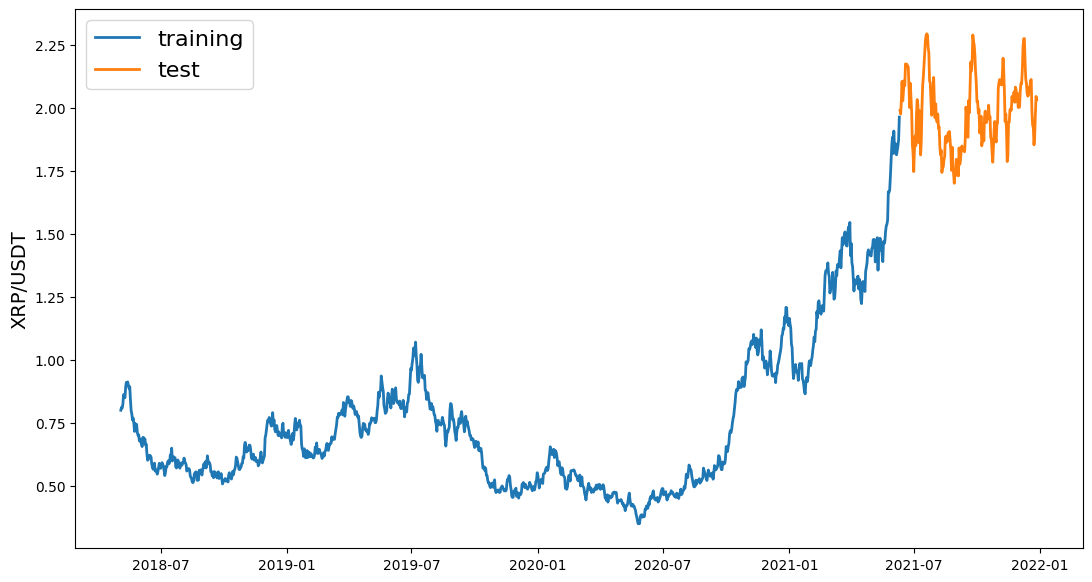

In [9]:
line_plot(train_data[aim], test_data[aim], 'training', 'test', title='')

In [10]:
def normalise_zero_base(continuous):
    return continuous / continuous.iloc[0] - 1

def normalise_min_max(continuous):
    return (continuous - continuous.min()) / (data.max() - continuous.min())

In [11]:
def extract_window_data(continuous, window_len=5, zero_base=True):
    window_data = []
    for idx in range(len(continuous) - window_len):
        tmp = continuous[idx: (idx + window_len)].copy()
        if zero_base:
            tmp = normalise_zero_base(tmp)
        window_data.append(tmp.values)
    return np.array(window_data)
def prepare_data(continuous, aim, window_len=10, zero_base=True, test_size=0.2):
    X_train = extract_window_data(train_data, window_len, zero_base)
    X_test = extract_window_data(test_data, window_len, zero_base)
    y_train = train_data[aim][window_len:].values
    y_test = test_data[aim][window_len:].values
    if zero_base:
        y_train = y_train / train_data[aim][:-window_len].values - 1
        y_test = y_test / test_data[aim][:-window_len].values - 1

    return train_data, test_data, X_train, X_test, y_train, y_test
import numpy as np

In [12]:
from tensorflow.keras import layers

In [13]:
def build_lstm_model(input_data, output_size, neurons, activ_func='linear',
                     dropout=0.2, loss='mse', optimizer='adam'):
    model = Sequential()
    model.add(LSTM(neurons, input_shape=(input_data.shape[1], input_data.shape[2])))
    model.add(Dropout(dropout))
    model.add(Dense(units=output_size))
    model.add(Activation(activ_func))

    model.compile(loss=loss, optimizer=optimizer)
    return model
np.random.seed(245)
window_len = 5
test_size = 0.2
zero_base = True
lstm_neurons = 50
epochs = 20
batch_size = 32
loss = 'mse'
dropout = 0.24
optimizer = 'adam'
train_data, test_data, X_train, X_test, y_train, y_test = prepare_data(
    data, aim, window_len=window_len, zero_base=zero_base, test_size=test_size)

In [14]:
print(X_train.shape)

(1129, 5, 6)


In [15]:
model = build_lstm_model(
    X_train, output_size=1, neurons=lstm_neurons, dropout=dropout, loss=loss,
    optimizer=optimizer)
modelfit = model.fit(
    X_train, y_train, validation_data=(X_test, y_test), epochs=epochs, batch_size=batch_size, verbose=1, shuffle=True)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0358 - val_loss: 0.0048
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0201 - val_loss: 0.0039
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0149 - val_loss: 0.0032
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0146 - val_loss: 0.0014
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0115 - val_loss: 0.0025
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0072 - val_loss: 0.0039
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0056 - val_loss: 0.0032
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0048 - val_loss: 0.0018
Epoch 9/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0037 - val_loss: 0.0014
Epoch 10/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0032 - val_loss: 0.0014
Epoch 11/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0029 - val_loss: 0.0015
Epoch 12/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0025 - val_loss: 0.0

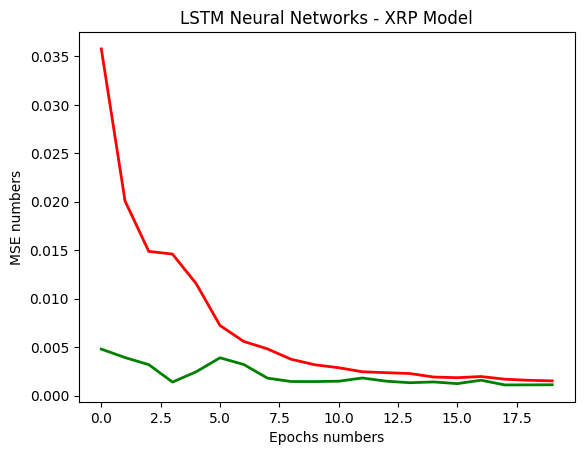

In [16]:
import matplotlib.pyplot as plt
plt.plot(modelfit.history['loss'],'r',linewidth=2, label='Training loss')
plt.plot(modelfit.history['val_loss'], 'g',linewidth=2, label='Validation loss')
plt.title('LSTM Neural Networks - XRP Model')
plt.xlabel('Epochs numbers')
plt.ylabel('MSE numbers')
plt.show()

In [20]:
targets = test_data[aim][window_len:]
preds = model.predict(X_test).squeeze()
mean_absolute_error(preds, y_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


0.026736947657109048

In [21]:
from sklearn.metrics import mean_squared_error
SCORE_MSE=mean_squared_error(preds, y_test)
SCORE_MSE

0.0011140023943567521

In [22]:
from sklearn.metrics import r2_score
r2_score=r2_score(y_test, preds)
r2_score*100

77.1443574293408

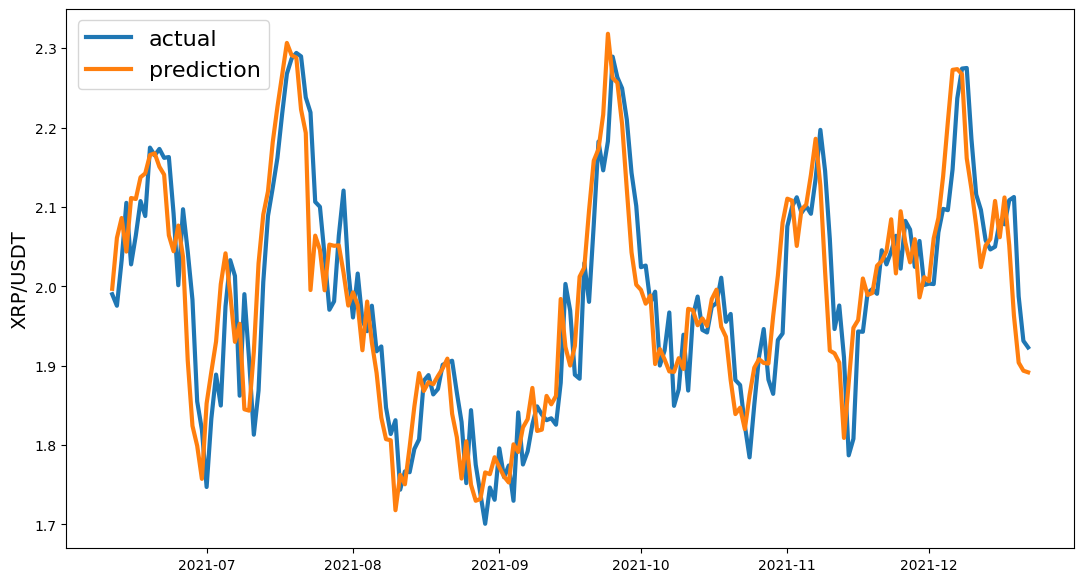

In [24]:
preds = test_data[aim].values[:-window_len] * (preds + 1)
preds = pd.Series(index=targets.index, data=preds)
line_plot(targets, preds, 'actual', 'prediction', lw=3)